### Cell 1 - Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Cell 2 - Loading the Dataset

In [2]:
df = pd.read_csv("credit_risk_regression_dataset.csv")

df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'credit_risk_regression_dataset.csv'

### Cell 3 - Inspect the data

In [4]:
print("Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nDescriptive Statistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Shape:
(200, 10)

Data Types:
Applicant_ID                  int64
Age                           int64
Annual_Income_INR             int64
Debt_to_Income_Ratio        float64
Late_Payments_12M             int64
Credit_History_Years          int64
Credit_Utilization_Ratio    float64
Existing_Loans                int64
Employment_Years              int64
Credit_Score                  int64
dtype: object

Descriptive Statistics:
       Applicant_ID         Age  Annual_Income_INR  Debt_to_Income_Ratio  \
count    200.000000  200.000000       2.000000e+02            200.000000   
mean     100.500000   43.860000       1.036260e+06              0.382550   
std       57.879185   13.105693       4.396210e+05              0.176726   
min        1.000000   21.000000       2.640000e+05              0.060000   
25%       50.750000   31.750000       6.450000e+05              0.250000   
50%      100.500000   45.000000       1.062000e+06              0.370000   
75%      150.250000   55.000000       1

### Cell 4 - Remove Applicant_ID

In [5]:
df = df.drop("Applicant_ID", axis=1)

df.head()

,Age,Annual_Income_INR,Debt_to_Income_Ratio,Late_Payments_12M,Credit_History_Years,Credit_Utilization_Ratio,Existing_Loans,Employment_Years,Credit_Score
0,61,576000,0.07,4,8,0.24,5,3,341
1,26,1536000,0.07,1,4,0.24,4,0,484
2,56,840000,0.50,8,14,0.23,4,8,300
3,31,1536000,0.26,2,4,0.91,2,1,413
4,26,1404000,0.11,5,5,0.77,5,7,322


### Cell 5 - Seperate X and Y

In [13]:
X = df.drop("Credit_Score", axis=1)
y = df["Credit_Score"]

print("Predictors:")
print(X.columns)

print("\nTarget:")
print(y.name)

Predictors:
Index(['Age', 'Annual_Income_INR', 'Debt_to_Income_Ratio', 'Late_Payments_12M',
       'Credit_History_Years', 'Credit_Utilization_Ratio', 'Existing_Loans',
       'Employment_Years'],
      dtype='str')

Target:
Credit_Score


### Cell 6 - Train and Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

X:
   Age  Annual_Income_INR  Debt_to_Income_Ratio  Late_Payments_12M  \
0   61             576000                  0.07                  4   
1   26            1536000                  0.07                  1   
2   56             840000                  0.50                  8   
3   31            1536000                  0.26                  2   
4   26            1404000                  0.11                  5   

   Credit_History_Years  Credit_Utilization_Ratio  Existing_Loans  \
0                     8                      0.24               5   
1                     4                      0.24               4   
2                    14                      0.23               4   
3                     4                      0.91               2   
4                     5                      0.77               5   

   Employment_Years  
0                 3  
1                 0  
2                 8  
3                 1  
4                 7  

y:
0    341
1    484
2    30

### Cell 7 - Fit Multiple Linear Regression Model on training data

In [14]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


### Cell 8 - Predict Test Data

In [15]:
y_pred = model.predict(X_test)

print("Predicted Credit Scores:")
print(y_pred)

Predicted Credit Scores:
[349.35825813 335.15482264 224.6296214  460.09603348 422.87231204
 368.1813981  355.01060414 404.85037074 490.95450988 359.93092123
 383.4863451  350.3911842  347.70824021 395.60526402 472.91671797
 441.05533632 467.98329062 338.30761939 407.48784591 279.09839247
 412.7168961  398.32616104 327.61147222 390.13046506 375.68978694
 318.71220974 363.51450561 279.79916223 421.91608535 350.07965161
 325.15666777 349.96214034 270.19476716 380.46920407 321.23491285
 460.08844549 462.0781363  415.18489025 311.91502395 479.23937071]


### Cell 9 - Evaluate the Model

In [16]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 22.129091316066216
MSE : 719.4408881508631
RMSE: 26.82239527243723
R²  : 0.8257714701798505


### Cell 10 - Interpret Coefficients and inspect residual plots

#### A. Coefficients

In [17]:
coefficients = pd.Series(
    model.coef_,
    index=X.columns
)

print("Model Coefficients:")
print(coefficients)

Model Coefficients:
Age                          -0.054044
Annual_Income_INR             0.000086
Debt_to_Income_Ratio       -138.191201
Late_Payments_12M           -16.219479
Credit_History_Years          2.805101
Credit_Utilization_Ratio    -65.775940
Existing_Loans               -4.594719
Employment_Years              1.854367
dtype: float64


#### B. Residuals

In [18]:
residuals = y_test - y_pred

print("Residuals:")
print(residuals)

Residuals:
95    -24.358258
15    -33.154823
30     75.370379
158    -2.096033
128   -15.872312
115   -44.181398
69    -13.010604
170   -33.850371
174    46.045490
45    -51.930921
66    -30.486345
182   -42.391184
165    -9.708240
78    -18.605264
186    -7.916718
177   -28.055336
56     -2.983291
152   -20.307619
82    -36.487846
68     20.901608
124    -7.716896
16    -29.326161
148   -27.611472
93     -0.130465
65    -23.689787
60    -18.712210
84    -25.514506
67     20.200838
125     9.083915
132    -9.079652
9     -25.156668
18    -11.962140
55     29.805233
75     13.530796
150   -21.234913
104     4.911555
135    14.921864
137   -18.184890
164   -11.915024
76      4.760629
Name: Credit_Score, dtype: float64


#### C. Residual plot

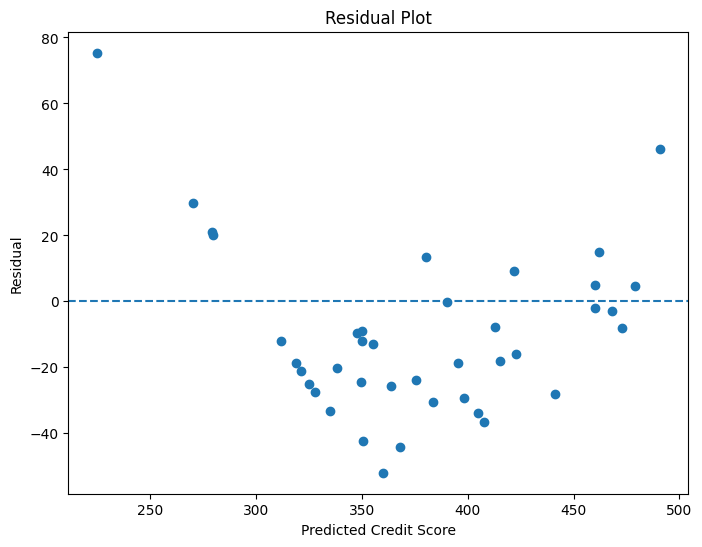

In [19]:
plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Credit Score")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.show()

### Cell 11 - Check for assumptions

#### A. Correlation Heatmap

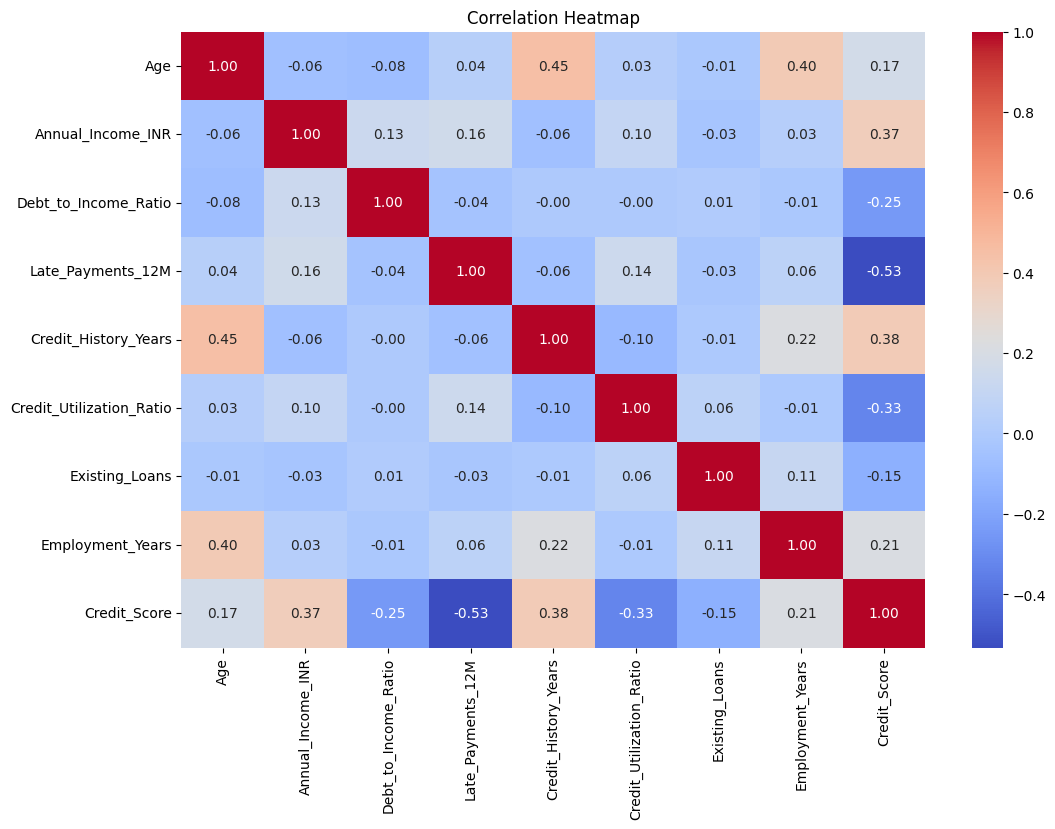

In [20]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

#### B. Actual VS Predicted

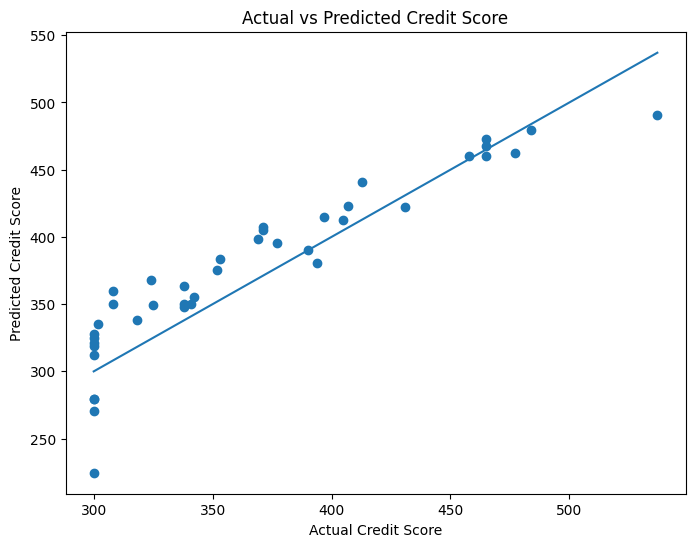

In [21]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.xlabel("Actual Credit Score")
plt.ylabel("Predicted Credit Score")
plt.title("Actual vs Predicted Credit Score")

plt.show()

### Cell 12 - New Applicant

In [22]:
new_applicant = pd.DataFrame({
    "Age": [25],
    "Annual_Income_INR": [500000],
    "Debt_to_Income_Ratio": [0.30],
    "Late_Payments_12M": [1],
    "Credit_History_Years": [4],
    "Credit_Utilization_Ratio": [0.25],
    "Existing_Loans": [2],
    "Employment_Years": [3]
})

predicted_score = model.predict(new_applicant)

print("Predicted Credit Score:", predicted_score[0])

Predicted Credit Score: 385.26294568101645
